In [3]:
!pip install yfinance
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = ['THYAO.IS', 'GARAN.IS', 'ASELS.IS', 'TUPRS.IS']

df = yf.download(tickers, start='2024-01-01', auto_adjust=True)

data = df['Close']
data = data.ffill().dropna()

data.head()

[*********************100%***********************]  4 of 4 completed


Ticker,ASELS.IS,GARAN.IS,THYAO.IS,TUPRS.IS
Date,,,,
2024-01-02,46.763844,52.167839,230.935410,108.066460
2024-01-03,46.464710,50.084671,224.781052,105.439850
2024-01-04,47.322212,51.059769,227.907074,107.841316
2024-01-05,47.302273,50.882484,233.670700,107.916374
2024-01-08,47.501690,55.048817,236.992111,105.064606


In [4]:

daily_returns = data.pct_change().dropna()

cumulative_returns = (1 + daily_returns).cumprod() - 1

rolling_volatility = daily_returns.rolling(window=21).std() * np.sqrt(252)

thyao_prices = data['THYAO.IS']
sma_20 = thyao_prices.rolling(window=20).mean()
sma_50 = thyao_prices.rolling(window=50).mean()

daily_returns.head()

Ticker,ASELS.IS,GARAN.IS,THYAO.IS,TUPRS.IS
Date,,,,
2024-01-03,-0.006397,-0.039932,-0.026650,-0.024306
2024-01-04,0.018455,0.019469,0.013907,0.022776
2024-01-05,-0.000421,-0.003472,0.025289,0.000696
2024-01-08,0.004216,0.081881,0.014214,-0.026426
2024-01-09,-0.014693,0.008052,0.001237,-0.013571


In [5]:

rolling_max = thyao_prices.cummax()
drawdown = (thyao_prices - rolling_max) / rolling_max
max_drawdown = drawdown.min()

print(f"THYAO Maximum Drawdown: %{max_drawdown * 100:.2f}")

annualized_returns = daily_returns.mean() * 252

annualized_volatility = daily_returns.std() * np.sqrt(252)

sharpe_ratio = annualized_returns / annualized_volatility

summary_table = pd.DataFrame({
    'Yıllık Getiri (%)': (annualized_returns * 100).round(2),
    'Yıllık Volatilite (%)': (annualized_volatility * 100).round(2),
    'Sharpe Oranı': sharpe_ratio.round(2)
})

print("\n--- RİSK VE GETİRİ KARŞILAŞTIRMA TABLOSU ---")
summary_table

THYAO Maximum Drawdown: %-24.40

--- RİSK VE GETİRİ KARŞILAŞTIRMA TABLOSU ---


,Yıllık Getiri (%),Yıllık Volatilite (%),Sharpe Oranı
Ticker,,,
ASELS.IS,82.29,43.53,1.89
GARAN.IS,40.67,38.58,1.05
THYAO.IS,11.69,31.07,0.38
TUPRS.IS,52.08,33.01,1.58


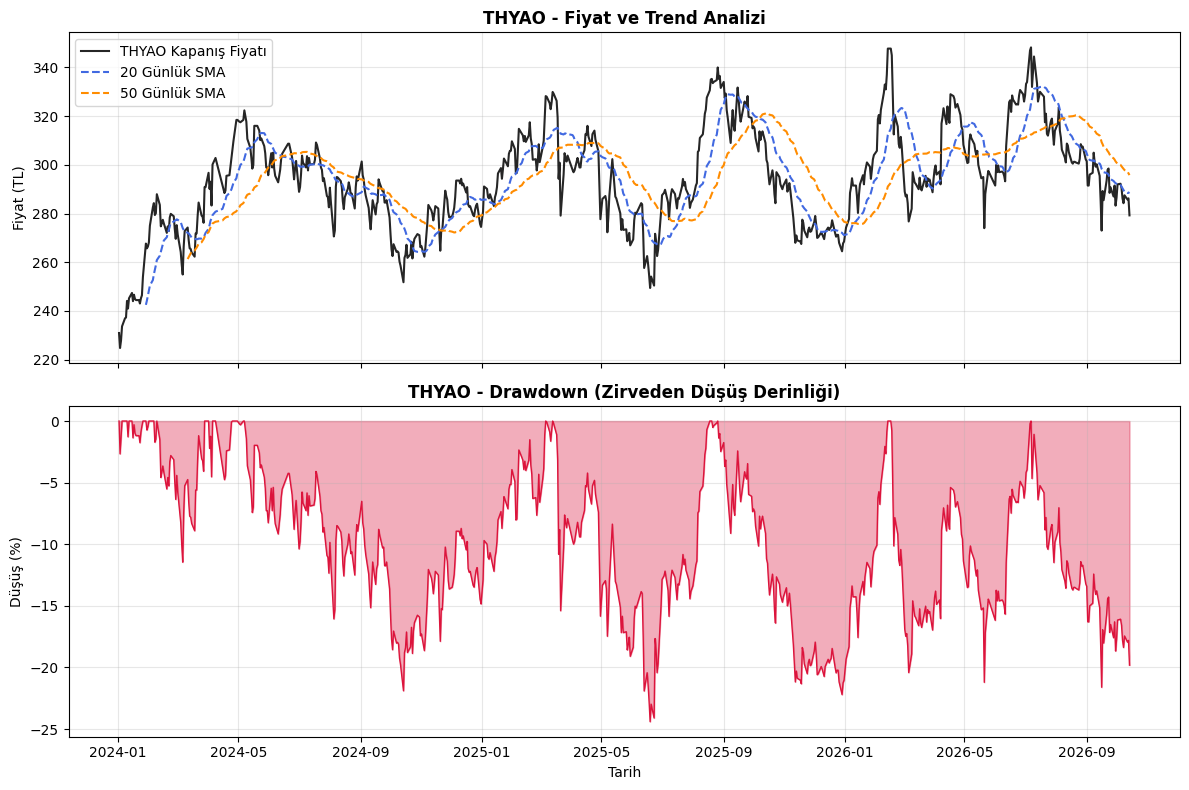

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(thyao_prices.index, thyao_prices, label='THYAO Kapanış Fiyatı', color='black', alpha=0.85)
axes[0].plot(sma_20.index, sma_20, label='20 Günlük SMA', color='royalblue', linestyle='--')
axes[0].plot(sma_50.index, sma_50, label='50 Günlük SMA', color='darkorange', linestyle='--')
axes[0].set_title('THYAO - Fiyat ve Trend Analizi', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Fiyat (TL)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

axes[1].fill_between(drawdown.index, drawdown * 100, 0, color='crimson', alpha=0.35, label='Drawdown (%)')
axes[1].plot(drawdown.index, drawdown * 100, color='crimson', linewidth=1)
axes[1].set_title('THYAO - Drawdown (Zirveden Düşüş Derinliği)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Düşüş (%)')
axes[1].set_xlabel('Tarih')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

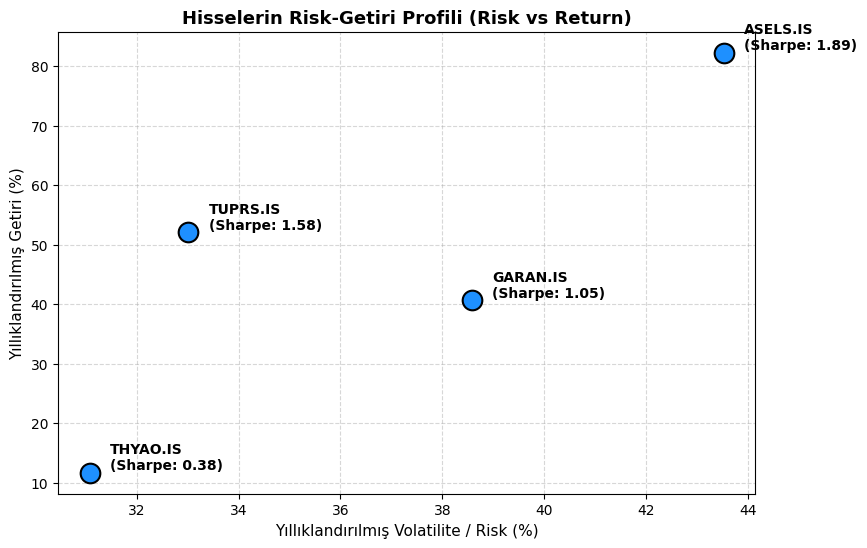

In [8]:
plt.figure(figsize=(9, 6))

plt.scatter(summary_table['Yıllık Volatilite (%)'],
            summary_table['Yıllık Getiri (%)'],
            s=200, color='dodgerblue', edgecolors='black', linewidth=1.5, zorder=3)

for ticker in summary_table.index:
    x = summary_table.loc[ticker, 'Yıllık Volatilite (%)']
    y = summary_table.loc[ticker, 'Yıllık Getiri (%)']
    sharpe = summary_table.loc[ticker, 'Sharpe Oranı']
    plt.annotate(f"{ticker}\n(Sharpe: {sharpe})",
                 (x + 0.4, y + 0.5),
                 fontsize=10, fontweight='bold')

plt.title('Hisselerin Risk-Getiri Profili (Risk vs Return)', fontsize=13, fontweight='bold')
plt.xlabel('Yıllıklandırılmış Volatilite / Risk (%)', fontsize=11)
plt.ylabel('Yıllıklandırılmış Getiri (%)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5, zorder=0)

plt.show()

In [9]:
data.tail()

Ticker,ASELS.IS,GARAN.IS,THYAO.IS,TUPRS.IS
Date,,,,
2026-10-08,348.75,128.500000,284.25,392.25
2026-10-09,351.25,129.300003,287.50,386.25
2026-10-12,341.75,129.800003,285.75,384.75
2026-10-13,350.75,131.300003,286.25,385.75
2026-10-14,348.00,130.500000,279.25,391.00
